# Corpo rigido — Capitolo VII Hairer–Lubich–Wanner

Sono confrontati:
- metodo del punto medio implicito;
- punto medio sferico;
- splitting esplicito.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from time import perf_counter

plt.rcParams['figure.figsize'] = (11, 4)


## Funzione di punto fisso

In [2]:
def pto_fisso(phi, x0, tol=1e-12, maxiter=1000):
    """Iterazione di punto fisso x_{k+1} = phi(x_k)."""
    x = np.asarray(x0, dtype=float).copy()

    for k in range(maxiter):
        x_new = np.asarray(phi(x), dtype=float)
        if np.linalg.norm(x_new - x) <= tol * (1.0 + np.linalg.norm(x_new)):
            return x_new
        x = x_new

    raise RuntimeError(f"Punto fisso non convergente dopo {maxiter} iterazioni")


## Dati del problema

In [3]:
# Per rendere i risultati riproducibili puoi fissare un seed.
# Commenta la riga seguente se vuoi dati casuali diversi a ogni esecuzione.
np.random.seed(1)

T = 20.0
h = 0.1
itermax = int(np.floor(T / h))

I = np.abs(np.random.randn(3))

J = np.random.randn(3, 3)
J = J + J.T

m0 = np.random.randn(3)
m00 = m0.copy()

def H(m):
    quadratic = 0.5 * np.dot(m, I * m)
    qJ = 0.5 * np.dot(m, J @ m)
    return quadratic + np.log(qJ)

def L(m):
    return 0.5 * np.linalg.norm(m)**2

def f(m):
    qJ = 0.5 * np.dot(m, J @ m)
    return np.cross(m, I * m + (J @ m) / qJ)

H0 = H(m00)
L0 = L(m00)

print('I =', I)
print('J =\n', J)
print('m(0) =', m00)
print('H(m0) =', H0)
print('L(m0) =', L0)


I = [1.62434536 0.61175641 0.52817175]
J =
 [[-2.14593724  2.61021939 -2.55090907]
 [ 2.61021939 -1.5224138   1.78114703]
 [-2.55090907  1.78114703 -4.12028142]]
m(0) = [-0.3224172  -0.38405435  1.13376944]
H(m0) = nan
L(m0) = 0.7684418745786349


/tmp/ipykernel_416848/2477023262.py:20: RuntimeWarning: invalid value encountered in log
  return quadratic + np.log(qJ)


## 1. Punto medio implicito

/tmp/ipykernel_416848/2477023262.py:20: RuntimeWarning: invalid value encountered in log
  return quadratic + np.log(qJ)


Tempo: 0.044027 s


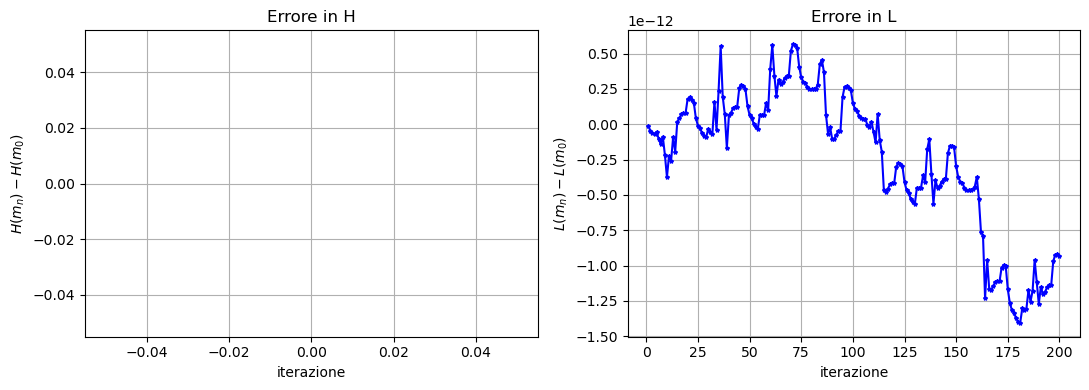

In [4]:
m0 = m00.copy()

H_err_mid = []
L_err_mid = []

tic = perf_counter()

for iteration in range(1, itermax + 1):
    m_old = m0.copy()

    # MATLAB:
    # pm = @(m) m0 + h*f(.5*(m+m0));
    phi = lambda m, m_old=m_old: m_old + h * f(0.5 * (m + m_old))
    m0 = pto_fisso(phi, m_old)

    H_err_mid.append(H(m0) - H0)
    L_err_mid.append(L(m0) - L0)

toc = perf_counter() - tic
print(f'Tempo: {toc:.6f} s')

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(range(1, itermax + 1), H_err_mid, 'r-*', markersize=3)
ax[0].set_title('Errore in H')
ax[0].set_xlabel('iterazione')
ax[0].set_ylabel(r'$H(m_n)-H(m_0)$')
ax[0].grid(True)

ax[1].plot(range(1, itermax + 1), L_err_mid, 'b-*', markersize=3)
ax[1].set_title('Errore in L')
ax[1].set_xlabel('iterazione')
ax[1].set_ylabel(r'$L(m_n)-L(m_0)$')
ax[1].grid(True)

plt.tight_layout()
plt.show()


## 2. Punto medio sferico

Tempo: 0.050706 s


/tmp/ipykernel_416848/2477023262.py:20: RuntimeWarning: invalid value encountered in log
  return quadratic + np.log(qJ)


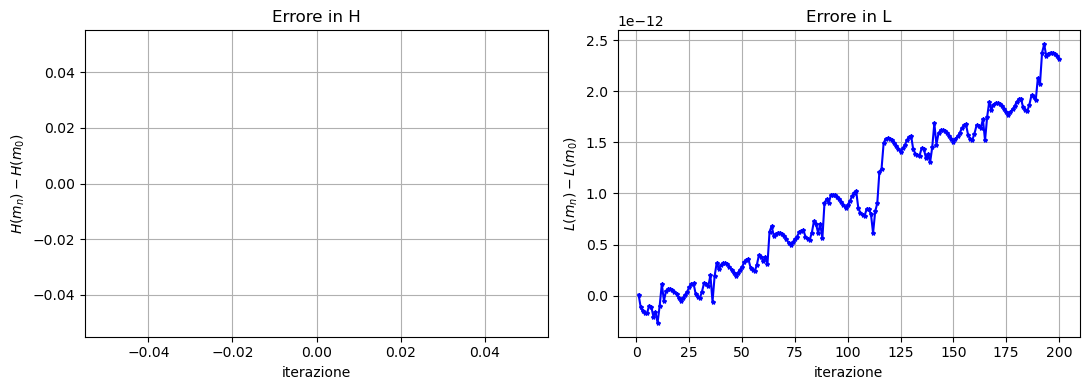

In [5]:
m0 = m00.copy()

H_err_sph = []
L_err_sph = []

tic = perf_counter()

for iteration in range(1, itermax + 1):
    m_old = m0.copy()

    # MATLAB:
    # pm = @(m) m0 + h*f((m+m0)/norm(m+m0));
    def phi(m, m_old=m_old):
        s = m + m_old
        return m_old + h * f(s / np.linalg.norm(s))

    m0 = pto_fisso(phi, m_old)

    H_err_sph.append(H(m0) - H0)
    L_err_sph.append(L(m0) - L0)

toc = perf_counter() - tic
print(f'Tempo: {toc:.6f} s')

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(range(1, itermax + 1), H_err_sph, 'r-*', markersize=3)
ax[0].set_title('Errore in H')
ax[0].set_xlabel('iterazione')
ax[0].set_ylabel(r'$H(m_n)-H(m_0)$')
ax[0].grid(True)

ax[1].plot(range(1, itermax + 1), L_err_sph, 'b-*', markersize=3)
ax[1].set_title('Errore in L')
ax[1].set_xlabel('iterazione')
ax[1].set_ylabel(r'$L(m_n)-L(m_0)$')
ax[1].grid(True)

plt.tight_layout()
plt.show()


## 3. Splitting esplicito

/tmp/ipykernel_416848/2477023262.py:20: RuntimeWarning: invalid value encountered in log
  return quadratic + np.log(qJ)


Tempo: 0.010777 s


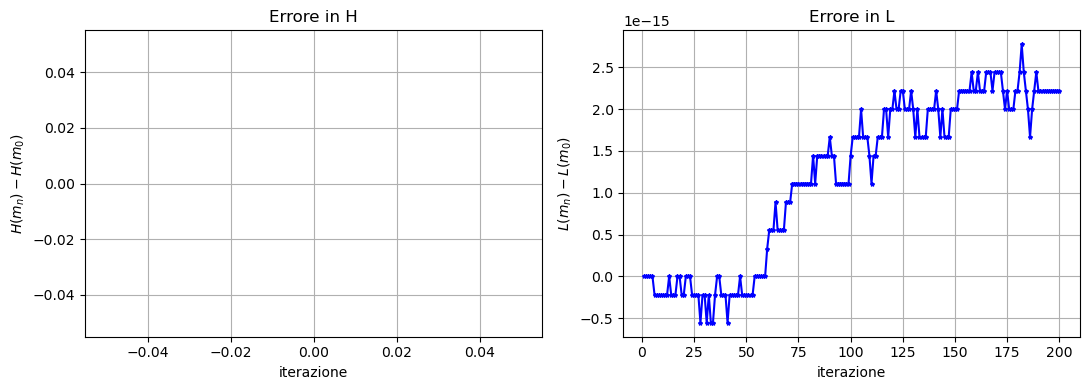

In [6]:
def R2(m):
    return np.array([
        [0.0, 0.0, -m[1] * (I[1] - I[0])],
        [0.0, 0.0, 0.0],
        [m[1] * (I[1] - I[0]), 0.0, 0.0]
    ])

def R3(m):
    return np.array([
        [0.0, m[2] * (I[2] - I[0]), 0.0],
        [-m[2] * (I[2] - I[0]), 0.0, 0.0],
        [0.0, 0.0, 0.0]
    ])

m0 = m00.copy()

H_err_split = []
L_err_split = []

tic = perf_counter()

for iteration in range(1, itermax + 1):
    m0 = expm((h / 2.0) * R2(m0)) @ m0
    m0 = expm(h * R3(m0)) @ m0
    m0 = expm((h / 2.0) * R2(m0)) @ m0

    H_err_split.append(H(m0) - H0)
    L_err_split.append(L(m0) - L0)

toc = perf_counter() - tic
print(f'Tempo: {toc:.6f} s')

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(range(1, itermax + 1), H_err_split, 'r-*', markersize=3)
ax[0].set_title('Errore in H')
ax[0].set_xlabel('iterazione')
ax[0].set_ylabel(r'$H(m_n)-H(m_0)$')
ax[0].grid(True)

ax[1].plot(range(1, itermax + 1), L_err_split, 'b-*', markersize=3)
ax[1].set_title('Errore in L')
ax[1].set_xlabel('iterazione')
ax[1].set_ylabel(r'$L(m_n)-L(m_0)$')
ax[1].grid(True)

plt.tight_layout()
plt.show()


## Confronto dei tre metodi

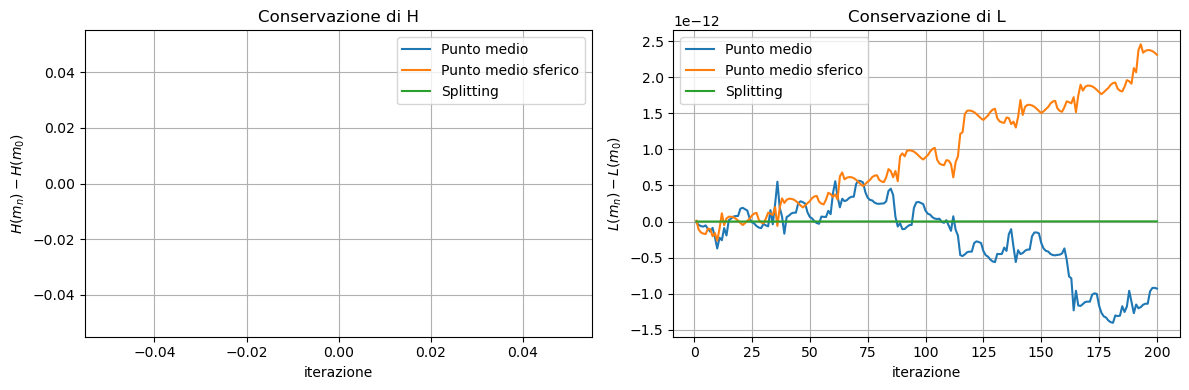

In [7]:
iterations = np.arange(1, itermax + 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(iterations, H_err_mid, label='Punto medio')
ax[0].plot(iterations, H_err_sph, label='Punto medio sferico')
ax[0].plot(iterations, H_err_split, label='Splitting')
ax[0].set_xlabel('iterazione')
ax[0].set_ylabel(r'$H(m_n)-H(m_0)$')
ax[0].set_title('Conservazione di H')
ax[0].grid(True)
ax[0].legend()

ax[1].plot(iterations, L_err_mid, label='Punto medio')
ax[1].plot(iterations, L_err_sph, label='Punto medio sferico')
ax[1].plot(iterations, L_err_split, label='Splitting')
ax[1].set_xlabel('iterazione')
ax[1].set_ylabel(r'$L(m_n)-L(m_0)$')
ax[1].set_title('Conservazione di L')
ax[1].grid(True)
ax[1].legend()

plt.tight_layout()
plt.show()
